# Browse Evals: ChatGPT Browsing Model Launch Analysis

Take-home assessment for OpenAI Data Scientist role.
**Goal:** Determine whether the new browsing model (Model A) is ready to launch.


##0 — Setup & Imports

In [1]:
import ast, warnings
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import scipy.stats as stats
import krippendorff

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.4f}".format)

COLOR_A   = "#10A37F"  # OpenAI green – Model A (release candidate)
COLOR_B   = "#1B1B1B"  # near-black   – Model B (baseline)
COLOR_TIE = "#6B7280"  # mid-gray     – ties

# Register a global OpenAI-branded Plotly template so every figure inherits it
import plotly.io as pio
pio.templates["oai"] = go.layout.Template(layout=go.Layout(
    font=dict(family="Inter, system-ui, sans-serif", color="#0D0D0D"),
    plot_bgcolor="#FFFFFF",
    paper_bgcolor="#FFFFFF",
    colorway=[COLOR_A, COLOR_B, COLOR_TIE, "#F59E0B", "#7C3AED"],
    title=dict(font=dict(size=16, color="#0D0D0D")),
))
PLOTLY_TEMPLATE = "plotly_white+oai"

DATA_PATH = "../../local_data/assessment/browse_evals_takehome_v1.1.csv"


##1 — Business Problem

OpenAI is evaluating a significant upgrade to ChatGPT's browsing model — the system
ChatGPT uses to search the web and summarise findings.
**Model A** = release candidate (new model), **Model B** = current production baseline.

Human graders compare A vs. B on the same prompts, providing:
- Individual quality scores (1–5) for each model
- A holistic comparison verdict (A>>B … A<<B)
- Error labels for shortcomings identified in each response

### Five questions to answer

| # | Question |
|---|----------|
| Q1 | Is the release candidate better than the existing model? |
| Q2 | Are we reaching diminishing returns, or is the model still improving? |
| Q3 | Are we happy with this pool of graders — signal or noise? |
| Q4 | What 1–3 other observations should we consider before launch? |
| Q5 | Should we launch or keep iterating? |


##2 — Data Schema

| Column | Type | Description |
|--------|------|-------------|
| `task` | string | Unique task ID |
| `created_at_pacific` | datetime | When the task entered the pool |
| `claimed_at_pacific` | datetime | When a grader picked up the task |
| `submitted_at_pacific` | datetime | When the grader submitted ratings |
| `batch` | string | Model-evolution batch ID |
| `scorecard_a` | int 1–5 | Standalone quality score for Model A |
| `scorecard_b` | int 1–5 | Standalone quality score for Model B |
| `response_quality_comparison` | ordinal | Holistic verdict: A>>B / A>B / A==B / A<B / A<<B |
| `completion_a_errors` | JSON list | Error categories flagged for Model A |
| `completion_b_errors` | JSON list | Error categories flagged for Model B |
| `grader` | string | Grader identifier |
| `prompt_category` | string | Model-labelled prompt category (8 values) |
| `unique_prompt_id` | string | Prompt identifier (same prompt can appear in multiple batches) |
| `prompt_text_length` | int | Character count of the prompt |

> **Note on error columns:** an empty list means no errors were *flagged*, not necessarily that no errors exist.
> **Note on comparison scale:** this is **ordinal**, not interval — A>>B is not "twice as good" as A>B.


##3 — Data Loading & Cleaning

In [2]:
dt_cols = ["created_at_pacific", "claimed_at_pacific", "submitted_at_pacific"]
df = pd.read_csv(DATA_PATH, parse_dates=dt_cols)

def parse_errors(val):
    if pd.isna(val) or str(val).strip() in ("[]", ""):
        return []
    try:
        return ast.literal_eval(val)
    except Exception:
        return []

df["errors_a"] = df["completion_a_errors"].apply(parse_errors)
df["errors_b"] = df["completion_b_errors"].apply(parse_errors)

# ── Derived columns ────────────────────────────────────────────────────────
df["score_diff"] = df["scorecard_a"] - df["scorecard_b"]
df["a_wins"]     = df["response_quality_comparison"].isin(["A > B", "A >> B"])
df["b_wins"]     = df["response_quality_comparison"].isin(["A < B", "A << B"])
df["tie"]        = df["response_quality_comparison"] == "A == B"

# Numeric encoding of comparison for ordinal analyses
COMP_MAP = {"A << B": 1, "A < B": 2, "A == B": 3, "A > B": 4, "A >> B": 5}
df["comp_numeric"] = df["response_quality_comparison"].map(COMP_MAP)

# Batch chronological order (derived from first-seen created_at date)
BATCH_ORDER = {
    "b74661183d": 1, "bb800a5bbf": 2, "b1bc0c57ef": 3, "ba0be5102c": 4,
    "b08a9dc797": 5, "bbba5ca703": 6, "b07acabe04": 7, "b06b812ca5": 8,
}
BATCH_LABELS = {
    "b74661183d": "B1 Jun 17", "bb800a5bbf": "B2 Jun 21",
    "b1bc0c57ef": "B3 Jun 24", "ba0be5102c": "B4 Jun 25",
    "b08a9dc797": "B5 Jun 26", "bbba5ca703": "B6 Jun 27",
    "b07acabe04": "B7 Jul 1",  "b06b812ca5": "B8 Jul 12",
}
df["batch_order"] = df["batch"].map(BATCH_ORDER)
df["batch_label"] = df["batch"].map(BATCH_LABELS)

# Grader task count (volume proxy)
grader_counts = df["grader"].value_counts().rename("grader_task_count")
df = df.join(grader_counts, on="grader")

# ⚠️ GOTCHA: claim→submit time is NOT a reliable effort proxy.
# Some graders show 2,000+ min averages — they claimed a task and returned the next day.
# Winsorise at 4 h (240 min) for any effort-based analysis.
df["time_to_submit_min"] = (
    df["submitted_at_pacific"] - df["claimed_at_pacific"]
).dt.total_seconds() / 60
df["time_to_submit_min_cap"] = df["time_to_submit_min"].clip(upper=240)

print(f"Rows: {len(df):,}  |  Columns: {df.shape[1]}")
print(f"Date range: {df['created_at_pacific'].min().date()} → {df['created_at_pacific'].max().date()}")
print(f"Batches: {df['batch'].nunique()}  |  Graders: {df['grader'].nunique()}  |  Prompt categories: {df['prompt_category'].nunique()}")


Rows: 2,699  |  Columns: 26
Date range: 2024-06-17 → 2024-07-12
Batches: 8  |  Graders: 61  |  Prompt categories: 8


##4 — Data Quality & Exploratory Analysis

### 4.1 Basic quality checks

In [3]:
print("=== Null counts ===")
print(df[["scorecard_a","scorecard_b","response_quality_comparison",
          "grader","prompt_category","unique_prompt_id"]].isnull().sum())

print("\n=== Score ranges ===")
print(df[["scorecard_a","scorecard_b","score_diff"]].describe().T)

print("\n=== Comparison value counts ===")
print(df["response_quality_comparison"].value_counts())


=== Null counts ===
scorecard_a                    0
scorecard_b                    0
response_quality_comparison    0
grader                         0
prompt_category                0
unique_prompt_id               0
dtype: int64

=== Score ranges ===
                count   mean    std     min     25%    50%    75%    max
scorecard_a 2699.0000 3.5769 1.0977  1.0000  3.0000 4.0000 4.0000 5.0000
scorecard_b 2699.0000 3.0489 1.1554  1.0000  2.0000 3.0000 4.0000 5.0000
score_diff  2699.0000 0.5280 1.4781 -4.0000 -1.0000 1.0000 2.0000 4.0000

=== Comparison value counts ===
response_quality_comparison
A > B     754
A >> B    703
A == B    549
A < B     464
A << B    229
Name: count, dtype: int64


### 4.2 Score distributions

In [4]:
fig = go.Figure()
for col, name, color in [("scorecard_a","Model A",COLOR_A), ("scorecard_b","Model B",COLOR_B)]:
    fig.add_trace(go.Histogram(
        x=df[col], name=name, opacity=0.72,
        marker_color=color, xbins=dict(start=0.5, end=5.5, size=1)
    ))
fig.update_layout(
    template=PLOTLY_TEMPLATE, barmode="overlay",
    title="Score distributions (1–5) — Model A vs Model B",
    xaxis_title="Score", yaxis_title="Count", legend_title="Model"
)
fig.show()


### 4.3 Score difference (A − B)

In [5]:
fig = px.histogram(
    df, x="score_diff", color_discrete_sequence=[COLOR_A],
    template=PLOTLY_TEMPLATE,
    title="Score difference (scorecard_A − scorecard_B)",
    labels={"score_diff": "Score difference (A − B)"},
)
fig.add_vline(x=0, line_dash="dash", line_color="black", annotation_text="Parity")
fig.show()
print(f"Mean score diff: {df['score_diff'].mean():.3f}  |  Median: {df['score_diff'].median():.1f}")


Mean score diff: 0.528  |  Median: 1.0


### 4.4 Batch sizes & date range

In [6]:
# ⚠️ GOTCHA: Batch sizes vary from ~94 to ~969.
# Small batches have much wider confidence intervals — always report uncertainty.
batch_summary = (
    df.groupby(["batch_order","batch_label","batch"])
    .agg(n=("task","count"), first_date=("created_at_pacific","min"))
    .reset_index()
    .sort_values("batch_order")
)
display(batch_summary[["batch_label","n","first_date"]].reset_index(drop=True))

fig = px.bar(
    batch_summary, x="batch_label", y="n", text="n",
    template=PLOTLY_TEMPLATE, color_discrete_sequence=[COLOR_A],
    title="Tasks per batch (chronological order)",
    labels={"batch_label":"Batch","n":"Number of tasks"},
)
fig.update_traces(textposition="outside")
fig.show()


,batch_label,n,first_date
0,B1 Jun 17,97,2024-06-17 21:52:05.076
1,B2 Jun 21,94,2024-06-21 22:07:52.283
2,B3 Jun 24,98,2024-06-24 09:13:09.665
3,B4 Jun 25,99,2024-06-25 21:56:31.164
4,B5 Jun 26,467,2024-06-26 22:07:15.101
5,B6 Jun 27,426,2024-06-27 19:53:55.038
6,B7 Jul 1,969,2024-07-01 13:51:15.436
7,B8 Jul 12,449,2024-07-12 00:23:38.586


### 4.5 Prompt categories

In [7]:
cat_counts = df["prompt_category"].value_counts().reset_index()
cat_counts.columns = ["category", "count"]
fig = px.bar(
    cat_counts, x="count", y="category", orientation="h",
    template=PLOTLY_TEMPLATE, color_discrete_sequence=[COLOR_A],
    title="Tasks by prompt category",
    labels={"count":"Number of tasks","category":""},
)
fig.update_layout(yaxis=dict(categoryorder="total ascending"))
fig.show()


### 4.6 Repeated prompts across batches

> **⚠️ GOTCHA — Repeated prompts are intentional, not duplicates.**
> 490 unique prompt IDs appear in **all 8 batches**. This is the study design:
> the same prompts are re-evaluated as the model evolves, enabling a clean
> within-prompt trend analysis. **Do NOT deduplicate rows.**


In [8]:
prompt_batch_counts = df.groupby("unique_prompt_id")["batch"].nunique()
print(f"Unique prompts: {df['unique_prompt_id'].nunique()}")
print(f"Prompts appearing in all 8 batches: {(prompt_batch_counts == 8).sum()}")
print(f"Distribution of batches per prompt:")
print(prompt_batch_counts.value_counts().sort_index())


Unique prompts: 984
Prompts appearing in all 8 batches: 70
Distribution of batches per prompt:
batch
1    494
2     18
3     80
4    292
5      2
6      5
7     23
8     70
Name: count, dtype: int64


### 4.7 Category coverage varies across batches

In [9]:
# ⚠️ GOTCHA: 'Other' and 'Websites and Apps' are absent from early batches.
# Category composition shifts can masquerade as model improvement — check both.
cat_batch = df.groupby(["batch_label","prompt_category"]).size().reset_index(name="count")
pivot_cat = cat_batch.pivot(index="prompt_category", columns="batch_label", values="count").fillna(0)
# reorder columns chronologically
ordered_cols = [BATCH_LABELS[b] for b in sorted(BATCH_ORDER, key=BATCH_ORDER.get)]
pivot_cat = pivot_cat[[c for c in ordered_cols if c in pivot_cat.columns]]

fig = px.imshow(
    pivot_cat, text_auto=True, aspect="auto",
    color_continuous_scale="Blues", template=PLOTLY_TEMPLATE,
    title="Task count by category × batch (coverage map)",
    labels={"x":"Batch","y":"Category","color":"Count"},
)
fig.show()


##5 — Q1: Is the Release Candidate Better?

**Approach:**
- Overall win/tie/loss rates with 95% bootstrap confidence intervals
- Wilcoxon signed-rank test on paired score differences (non-parametric, correct for ordinal data)
- Per-category breakdown with error bars

> **⚠️ GOTCHA: Comparison scale is ordinal, not interval.**
> Do not use paired t-tests or Pearson correlation on `response_quality_comparison`.
> Wilcoxon signed-rank on `score_diff` is appropriate because the scorecards are Likert 1–5.


In [10]:
def bootstrap_ci(data, stat_fn=np.mean, n_boot=5000, ci=0.95):
    rng = np.random.default_rng(42)
    boot = [stat_fn(rng.choice(data, size=len(data), replace=True)) for _ in range(n_boot)]
    lo = np.percentile(boot, (1 - ci) / 2 * 100)
    hi = np.percentile(boot, (1 + ci) / 2 * 100)
    return lo, hi

n = len(df)
a_rate = df["a_wins"].mean()
b_rate = df["b_wins"].mean()
t_rate = df["tie"].mean()

a_lo, a_hi = bootstrap_ci(df["a_wins"].values.astype(float))
b_lo, b_hi = bootstrap_ci(df["b_wins"].values.astype(float))

print("=== Overall verdict ===")
print(f"  Model A wins: {a_rate:.1%}  (95% CI: {a_lo:.1%}–{a_hi:.1%})")
print(f"  Ties:         {t_rate:.1%}")
print(f"  Model B wins: {b_rate:.1%}  (95% CI: {b_lo:.1%}–{b_hi:.1%})")

# Wilcoxon signed-rank test
stat_w, p_w = stats.wilcoxon(df["score_diff"].dropna())
print(f"\nWilcoxon signed-rank test on score_diff:")
print(f"  statistic={stat_w:.0f}, p={p_w:.4e}")
print(f"  {'Significant' if p_w < 0.05 else 'Not significant'} at α=0.05")


=== Overall verdict ===
  Model A wins: 54.0%  (95% CI: 52.1%–55.9%)
  Ties:         20.3%
  Model B wins: 25.7%  (95% CI: 24.0%–27.3%)

Wilcoxon signed-rank test on score_diff:
  statistic=664164, p=4.9047e-69
  Significant at α=0.05


In [11]:
# Donut chart — overall verdict
labels = ["A wins", "Tie", "B wins"]
values = [df["a_wins"].sum(), df["tie"].sum(), df["b_wins"].sum()]
colors = [COLOR_A, COLOR_TIE, COLOR_B]

fig = go.Figure(go.Pie(
    labels=labels, values=values, hole=0.55,
    marker_colors=colors,
    textinfo="label+percent",
    hovertemplate="%{label}: %{value} tasks (%{percent})<extra></extra>",
))
fig.update_layout(
    template=PLOTLY_TEMPLATE,
    title=f"Q1: Overall Model Comparison  (n={n:,})",
    annotations=[dict(text=f"<b>A wins<br>{a_rate:.0%}</b>", x=0.5, y=0.5,
                      font_size=18, showarrow=False)],
)
fig.show()


In [12]:
# Win rate by prompt category with 95% CI
cat_stats = []
for cat, grp in df.groupby("prompt_category"):
    a = grp["a_wins"].values.astype(float)
    b = grp["b_wins"].values.astype(float)
    cat_stats.append({
        "category": cat, "n": len(grp),
        "a_rate": a.mean(),
        "b_rate": b.mean(),
        "a_lo": bootstrap_ci(a)[0], "a_hi": bootstrap_ci(a)[1],
        "b_lo": bootstrap_ci(b)[0], "b_hi": bootstrap_ci(b)[1],
    })
cat_df = pd.DataFrame(cat_stats).sort_values("a_rate", ascending=False)

fig = go.Figure()
for model, rate_col, lo_col, hi_col, color in [
    ("Model A wins", "a_rate","a_lo","a_hi", COLOR_A),
    ("Model B wins", "b_rate","b_lo","b_hi", COLOR_B),
]:
    fig.add_trace(go.Bar(
        x=cat_df["category"], y=cat_df[rate_col],
        name=model, marker_color=color,
        error_y=dict(
            type="data",
            symmetric=False,
            array=(cat_df[hi_col] - cat_df[rate_col]).tolist(),
            arrayminus=(cat_df[rate_col] - cat_df[lo_col]).tolist(),
        ),
        hovertemplate="%{x}<br>Rate: %{y:.1%}<extra>" + model + "</extra>",
    ))
fig.update_layout(
    template=PLOTLY_TEMPLATE, barmode="group",
    title="Q1: Win rate by prompt category (95% CI)",
    yaxis_title="Win rate", yaxis_tickformat=".0%",
    xaxis_title="Prompt category", legend_title="",
)
fig.show()


> **⚠️ GOTCHA — Simpson's Paradox risk.**
> If the category mix differs across batches, shifts in the *overall* win rate
> may partly reflect a changing composition rather than pure model improvement.
> Always verify per-category trends alongside the aggregate (§6).


##6 — Q2: Diminishing Returns or Still Improving?

We use the chronological batch ordering to track A's win rate over time.
Then we leverage the **repeated-measures structure** (490 prompts appear in all 8 batches)
for a within-prompt trend — a much cleaner signal that controls for prompt difficulty.

**Statistical test:** Kendall's τ (equivalent to Mann-Kendall) on batch-level win rates.


In [13]:
# Per-batch win rate with 95% CI
batch_stats = []
for (order, label), grp in df.groupby(["batch_order","batch_label"]):
    a = grp["a_wins"].values.astype(float)
    lo, hi = bootstrap_ci(a)
    batch_stats.append({
        "batch_order": order, "batch_label": label,
        "n": len(grp), "a_rate": a.mean(), "ci_lo": lo, "ci_hi": hi,
    })
batch_df = pd.DataFrame(batch_stats).sort_values("batch_order")

# Mann-Kendall trend test via Kendall's tau
tau, p_mk = stats.kendalltau(batch_df["batch_order"], batch_df["a_rate"])
print(f"Mann-Kendall trend test:  τ = {tau:.3f},  p = {p_mk:.4f}")
print(f"  {'Significant positive trend' if tau > 0 and p_mk < 0.05 else 'No significant monotonic trend'}")

display(batch_df[["batch_label","n","a_rate","ci_lo","ci_hi"]].round(3))


Mann-Kendall trend test:  τ = 0.500,  p = 0.1087
  No significant monotonic trend


,batch_label,n,a_rate,ci_lo,ci_hi
0,B1 Jun 17,97,0.4430,0.3510,0.5460
1,B2 Jun 21,94,0.5210,0.4150,0.6280
2,B3 Jun 24,98,0.5410,0.4390,0.6330
3,B4 Jun 25,99,0.5250,0.4240,0.6260
4,B5 Jun 26,467,0.5440,0.4990,0.5890
5,B6 Jun 27,426,0.5610,0.5120,0.6080
6,B7 Jul 1,969,0.5430,0.5120,0.5740
7,B8 Jul 12,449,0.5370,0.4900,0.5810


In [14]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=batch_df["batch_label"], y=batch_df["a_rate"],
    mode="lines+markers", name="A win rate",
    line=dict(color=COLOR_A, width=2),
    marker=dict(size=8),
    error_y=dict(
        type="data", symmetric=False,
        array=(batch_df["ci_hi"] - batch_df["a_rate"]).tolist(),
        arrayminus=(batch_df["a_rate"] - batch_df["ci_lo"]).tolist(),
        color=COLOR_A,
    ),
    hovertemplate="%{x}<br>A win rate: %{y:.1%}<extra></extra>",
))
fig.add_hline(y=0.5, line_dash="dash", line_color="gray",
              annotation_text="50% parity", annotation_position="bottom right")
fig.update_layout(
    template=PLOTLY_TEMPLATE,
    title="Q2: A win rate over batches (chronological) with 95% CI",
    yaxis_title="A win rate", yaxis_tickformat=".0%",
    xaxis_title="Batch (chronological)",
)
fig.show()


### 6.2 Within-prompt view (removes prompt-difficulty confound)

In [15]:
# For prompts that appear in multiple batches, compute per-prompt win rate by batch
# This isolates the model-quality signal from prompt-level variation.
# ⚠️ GOTCHA: Repeated prompts are by design — do NOT treat them as duplicates.

repeated_prompts = df.groupby("unique_prompt_id")["batch"].nunique()
repeated_ids = repeated_prompts[repeated_prompts >= 4].index  # prompts in ≥4 batches

within_df = df[df["unique_prompt_id"].isin(repeated_ids)].copy()
within_batch = (
    within_df.groupby(["batch_order","batch_label"])["a_wins"]
    .agg(["mean","count"])
    .reset_index()
    .rename(columns={"mean":"a_rate","count":"n"})
    .sort_values("batch_order")
)
print(f"Using {within_df['unique_prompt_id'].nunique()} repeated prompts ({len(within_df):,} rows)")
display(within_batch.round(3))


Using 392 repeated prompts (1,929 rows)


,batch_order,batch_label,a_rate,n
0,1,B1 Jun 17,0.4430,97
1,2,B2 Jun 21,0.5210,94
2,3,B3 Jun 24,0.5410,98
3,4,B4 Jun 25,0.5250,99
4,5,B5 Jun 26,0.5540,388
5,6,B6 Jun 27,0.5630,380
6,7,B7 Jul 1,0.5040,389
7,8,B8 Jul 12,0.5520,384


In [16]:
# Side-by-side: all tasks vs repeated-prompt subset
fig = make_subplots(rows=1, cols=2, subplot_titles=[
    "All tasks (raw win rate per batch)",
    "Repeated prompts only (within-prompt view)",
])
for col_i, data in [(1, batch_df), (2, within_batch)]:
    fig.add_trace(go.Scatter(
        x=data["batch_label"], y=data["a_rate"],
        mode="lines+markers", name="A win rate",
        line=dict(color=COLOR_A, width=2), marker=dict(size=8),
        showlegend=(col_i == 1),
    ), row=1, col=col_i)
    fig.add_hline(y=0.5, line_dash="dash", line_color="gray", row=1, col=col_i)
fig.update_yaxes(tickformat=".0%", title_text="A win rate")
fig.update_layout(template=PLOTLY_TEMPLATE,
                  title="Q2: Trend analysis — all tasks vs repeated-prompt view")
fig.show()


##7 — Q3: Grader Quality — Signal or Noise?

We examine three aspects:
1. **Volume distribution** — are some graders doing nearly all the work?
2. **Inter-rater reliability** — do graders agree on the comparison verdict (Krippendorff's α)?
3. **Grader bias** — does any grader systematically favour one model?

> **⚠️ GOTCHA: Grader self-selection.**
> Graders *claim* tasks from a pool rather than being randomly assigned.
> A grader who dislikes real-time information queries might skip those tasks,
> making per-grader comparisons confounded with prompt-category preference.


In [17]:
# Volume distribution
grader_summary = (
    df.groupby("grader")
    .agg(
        task_count=("task","count"),
        a_win_rate=("a_wins","mean"),
        mean_score_diff=("score_diff","mean"),
    )
    .reset_index()
    .sort_values("task_count", ascending=False)
)
print(f"Total graders: {len(grader_summary)}")
print(f"Task count — min: {grader_summary['task_count'].min()},  "
      f"median: {grader_summary['task_count'].median():.0f},  "
      f"max: {grader_summary['task_count'].max()}")

low_vol = grader_summary[grader_summary["task_count"] < 10]
print(f"Low-volume graders (<10 tasks, excluded from bias analysis): {len(low_vol)}")


Total graders: 61
Task count — min: 1,  median: 27,  max: 175
Low-volume graders (<10 tasks, excluded from bias analysis): 11


In [18]:
fig = px.histogram(
    grader_summary, x="task_count", nbins=20,
    template=PLOTLY_TEMPLATE, color_discrete_sequence=[COLOR_A],
    title="Q3: Distribution of tasks per grader",
    labels={"task_count":"Tasks completed"},
)
fig.add_vline(x=10, line_dash="dash", line_color="orange",
              annotation_text="10-task threshold", annotation_position="top right")
fig.show()


### 7.2 Inter-rater reliability (Krippendorff's α, ordinal)

In [54]:
# Build a grader × prompt reliability matrix
# Each unique_prompt_id that was rated by ≥2 graders (across batches) provides a datapoint.
pivot_irr = df.pivot_table(
    index="grader", columns="unique_prompt_id",
    values="comp_numeric", aggfunc="first"
)
# krippendorff expects rows=raters, cols=items; NaN = missing
alpha_ordinal = krippendorff.alpha(
    reliability_data=pivot_irr.values,
    level_of_measurement="ordinal",
)
print(f"Krippendorff's α (ordinal): {alpha_ordinal:.4f}")
print()
print("Interpretation guide:")
print("  α < 0.20  → Poor agreement (noise dominates)")
print("  0.20–0.40 → Fair agreement")
print("  0.40–0.60 → Moderate agreement")
print("  0.60–0.80 → Substantial agreement")
print("  > 0.80    → Near-perfect agreement")


Krippendorff's α (ordinal): 0.1468

Interpretation guide:
  α < 0.20  → Poor agreement (noise dominates)
  0.20–0.40 → Fair agreement
  0.40–0.60 → Moderate agreement
  0.60–0.80 → Substantial agreement
  > 0.80    → Near-perfect agreement


In [56]:
df.head()

,task,created_at_pacific,claimed_at_pacific,batch,scorecard_a,scorecard_b,response_quality_comparison,completion_a_errors,completion_b_errors,submitted_at_pacific,grader,prompt_category,unique_prompt_id,prompt_text_length,errors_a,errors_b,score_diff,a_wins,b_wins,tie,comp_numeric,batch_order,batch_label,grader_task_count,time_to_submit_min,time_to_submit_min_cap,length_bin
0,t36db110e7,2024-06-17 21:53:09.043,2024-06-18 08:00:50.888,b74661183d,3,2,A > B,"[""Answer quality: Overly concise / 'Lazy' / no...","[""Answer quality: Overly concise / 'Lazy' / no...",2024-06-18 08:08:25.565,helen-b,People,p166,13,[Answer quality: Overly concise / 'Lazy' / not...,[Answer quality: Overly concise / 'Lazy' / not...,1,True,False,False,4,1,B1 Jun 17,91,7.5780,7.5780,≤20
1,t1545291e3,2024-06-17 21:52:45.937,2024-06-18 08:10:38.684,b74661183d,4,2,A >> B,[],"[""Answer quality: Factually incorrect"",""Answer...",2024-06-18 08:32:41.586,helen-b,Commerce,p93,35,[],"[Answer quality: Factually incorrect, Answer q...",2,True,False,False,5,1,B1 Jun 17,91,22.0484,22.0484,21–35
2,td97e8d611,2024-06-17 21:53:37.019,2024-06-18 08:17:48.039,b74661183d,4,3,A > B,"[""Sources quality: Missing a major source (e.g...","[""Sources quality: Missing a major source (e.g...",2024-06-18 08:32:46.512,brian-r,Commerce,p291,29,[Sources quality: Missing a major source (e.g....,[Sources quality: Missing a major source (e.g....,1,True,False,False,4,1,B1 Jun 17,175,14.9745,14.9745,21–35
3,t3a9cf1898,2024-06-17 21:53:43.412,2024-06-18 08:35:23.392,b74661183d,2,5,A << B,"[""Answer quality: Overly concise / 'Lazy' / no...",[],2024-06-18 08:42:12.220,marilyn-r,Information (Real-time),p320,41,[Answer quality: Overly concise / 'Lazy' / not...,[],-3,False,True,False,1,1,B1 Jun 17,79,6.8138,6.8138,36–55
4,t84d6bcbd9,2024-06-17 21:53:49.125,2024-06-18 08:05:40.534,b74661183d,2,3,A < B,"[""Answer quality: Poor presentation (broken / ...","[""Sources quality: Stale (most of sources are ...",2024-06-18 08:44:54.682,rachel-d,Entertainment,p966,35,[Answer quality: Poor presentation (broken / w...,[Sources quality: Stale (most of sources are o...,-1,False,True,False,2,1,B1 Jun 17,27,39.2358,39.2358,21–35


In [86]:
df['unique_prompt_id'].value_counts().to_frame().query("count >= 2").shape[0]

490

In [96]:
df['grader'].value_counts().tail(10)

grader
omar-m        8
grace-r       8
maria-b       7
marlene-l     7
courtney-s    7
mark-k        6
britney-b     5
janet-t       4
danielle-h    3
melissa-r     1
Name: count, dtype: int64

In [94]:
df.groupby(['unique_prompt_id'])['batch_label'].nunique().sort_values(ascending=False).to_frame().query("batch_label == 8").shape[0]

70

In [89]:
df.groupby(['unique_prompt_id', 'batch_label']).size().reset_index(name='count').sort_values('count', ascending=False)

,unique_prompt_id,batch_label,count
0,p1,B7 Jul 1,1
1802,p667,B7 Jul 1,1
1794,p661,B7 Jul 1,1
1795,p661,B8 Jul 12,1
1796,p662,B7 Jul 1,1
...,...,...,...
901,p36,B8 Jul 12,1
902,p360,B7 Jul 1,1
903,p361,B7 Jul 1,1
904,p362,B7 Jul 1,1


In [73]:
df.groupby(['unique_prompt_id'])['grader'].nunique().sort_values(ascending=False).to_frame()

,grader
unique_prompt_id,
p97,8
p774,8
p196,8
p433,8
p719,8
...,...
p557,1
p558,1
p559,1


In [80]:
pd.merge(
    df['unique_prompt_id'].value_counts().to_frame(),
    df.groupby(['unique_prompt_id'])['grader'].nunique().sort_values(ascending=False).to_frame(),
    on='unique_prompt_id'
).query("count != grader")

,count,grader
unique_prompt_id,,
p166,8,7
p93,8,7
p291,8,6
p320,8,5
p966,8,5
...,...,...
p549,3,2
p689,3,2
p714,3,2


In [84]:
df['errors_a'].apply(len).describe()

count   2699.0000
mean       1.3587
std        1.2338
min        0.0000
25%        0.0000
50%        1.0000
75%        2.0000
max        6.0000
Name: errors_a, dtype: float64

In [81]:
df['errors_a'].value_counts()

errors_a
[]                                                                                                                                                                                                                                                                                                                                                  730
[Answer quality: Poor presentation (broken / weird format)]                                                                                                                                                                                                                                                                                         184
[Answer quality: Overly concise / 'Lazy' / not actually answering the question]                                                                                                                                                                                                                                

In [82]:
df['errors_b'].value_counts()

errors_b
[]                                                                                                                                                                                                                                                                                                                    431
[Source references in answer: Insufficient (too few)]                                                                                                                                                                                                                                                                 326
[Source references in answer: Insufficient (too few), Sources quality: Missing a major source (e.g., LinkedIn for a prominent tech professional)]                                                                                                                                                                     152
[Sources quality: Missing a major source (e.g., L

In [70]:
import matplotlib.pyplot as plt

In [85]:
df['unique_prompt_id'].value_counts()

unique_prompt_id
p166    8
p93     8
p291    8
p320    8
p966    8
       ..
p439    1
p222    1
p278    1
p39     1
p559    1
Name: count, Length: 984, dtype: int64

(array([496.,  50., 123.,   0., 224.,  12.,   0.,  28.,  32.,  19.]),
 array([1. , 1.7, 2.4, 3.1, 3.8, 4.5, 5.2, 5.9, 6.6, 7.3, 8. ]),
 <BarContainer object of 10 artists>)

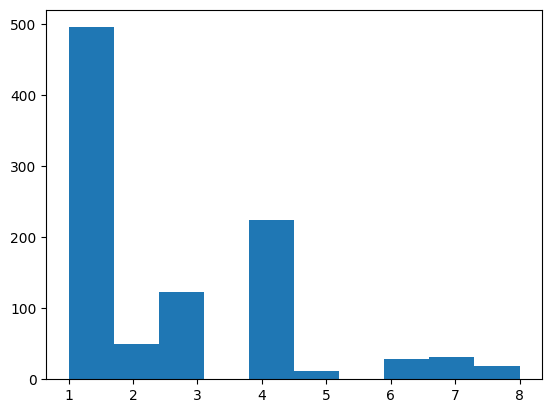

In [71]:
plt.hist(df.groupby(['unique_prompt_id'])['grader'].nunique().sort_values(ascending=False))

In [55]:
pivot_irr

unique_prompt_id,p1,p10,p100,p101,p102,p103,p104,p105,p106,p107,p108,p109,p11,p110,p111,...,p972,p973,p974,p975,p976,p977,p978,p979,p98,p980,p981,p982,p983,p984,p99
grader,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
adrian-h,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
alexander-f,NaN,NaN,NaN,5.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amanda-r,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,4.0000,NaN,NaN,NaN,2.0000,NaN,NaN,NaN,NaN,NaN,NaN
andrew-t,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0000,NaN,NaN,5.0000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anthony-h,NaN,NaN,NaN,5.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,2.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
thomas-c,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wanda-s,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
william-m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 7.3 Grader bias — does any grader systematically favour A or B?

In [20]:
# Restrict to graders with ≥10 tasks for reliable estimates
grader_bias = grader_summary[grader_summary["task_count"] >= 10].copy()

# Flag graders whose A-win rate is >2 std from the population mean
pop_mean = df["a_wins"].mean()
pop_std  = grader_bias["a_win_rate"].std()
grader_bias["z_score"] = (grader_bias["a_win_rate"] - pop_mean) / pop_std
grader_bias["outlier"]  = grader_bias["z_score"].abs() > 2

print(f"Population mean A-win rate: {pop_mean:.1%}")
print(f"Outlier graders (|z|>2): {grader_bias['outlier'].sum()}")
display(grader_bias[grader_bias["outlier"]][["grader","task_count","a_win_rate","z_score"]].sort_values("z_score"))


Population mean A-win rate: 54.0%
Outlier graders (|z|>2): 2


,grader,task_count,a_win_rate,z_score
46,nadia-c,41,0.2683,-2.2195
30,jennifer-d,16,0.8750,2.7397


In [21]:
grader_sorted = grader_bias.sort_values("a_win_rate")
fig = px.scatter(
    grader_sorted,
    x="a_win_rate", y="grader",
    color="outlier",
    color_discrete_map={True: "red", False: COLOR_A},
    size="task_count",
    template=PLOTLY_TEMPLATE,
    title="Q3: Grader A-win rate (bubble size = task volume)",
    labels={"a_win_rate":"A win rate","grader":"Grader","outlier":"Outlier (|z|>2)"},
    hover_data={"task_count":True,"z_score":":.2f"},
)
# Explicitly set y-axis order so graders are sorted by A-win rate (lowest at bottom, highest at top)
fig.update_layout(
    height=max(400, len(grader_bias)*14), yaxis_title="",
    yaxis=dict(categoryorder="array", categoryarray=grader_sorted["grader"].tolist()),
)
fig.add_vline(x=pop_mean, line_dash="dash", line_color="black",
              annotation_text=f"Pop mean {pop_mean:.0%}")
fig.add_vline(x=pop_mean - 2*pop_std, line_dash="dot", line_color="orange")
fig.add_vline(x=pop_mean + 2*pop_std, line_dash="dot", line_color="orange",
              annotation_text="±2σ", annotation_position="top right")
fig.show()


##8 — Q4: Additional Observations

Three insights worth reviewing before the launch decision.


### 8.1 Error pattern analysis — where does each model fail?

In [22]:
# ⚠️ GOTCHA: empty error list ≠ no errors — treat counts as lower bounds.
errors_a_long = (
    df[["task","errors_a"]].explode("errors_a")
    .dropna(subset=["errors_a"])
    .query("errors_a != ''")
    .assign(model="Model A")
    .rename(columns={"errors_a":"error"})
)
errors_b_long = (
    df[["task","errors_b"]].explode("errors_b")
    .dropna(subset=["errors_b"])
    .query("errors_b != ''")
    .assign(model="Model B")
    .rename(columns={"errors_b":"error"})
)
errors_long = pd.concat([errors_a_long, errors_b_long])

error_counts = (
    errors_long.groupby(["error","model"]).size()
    .reset_index(name="count")
)
# Normalise by total tasks to get error rate
error_counts["rate"] = error_counts["count"] / len(df)

fig = px.bar(
    error_counts.sort_values("rate", ascending=False),
    x="rate", y="error", color="model", orientation="h",
    barmode="group",
    color_discrete_map={"Model A": COLOR_A, "Model B": COLOR_B},
    template=PLOTLY_TEMPLATE,
    title="Q4a: Error rates by type and model (as % of all tasks)",
    labels={"rate":"Error rate","error":"Error type","model":""},
)
fig.update_xaxes(tickformat=".0%")
fig.update_layout(yaxis=dict(categoryorder="total ascending"), height=500)
fig.show()


### 8.2 Scorecard ↔ comparison internal consistency

In [23]:
# Verify the two signals are coherent: stronger comparison should correlate with larger score gap.
mean_diff_by_comp = (
    df.groupby("response_quality_comparison")["score_diff"]
    .agg(["mean","sem","count"])
    .reset_index()
    .rename(columns={"mean":"mean_diff","sem":"se","count":"n"})
)
mean_diff_by_comp["comp_numeric"] = mean_diff_by_comp["response_quality_comparison"].map(COMP_MAP)
mean_diff_by_comp = mean_diff_by_comp.sort_values("comp_numeric")

fig = px.scatter(
    mean_diff_by_comp,
    x="comp_numeric", y="mean_diff",
    error_y="se", size="n",
    text="response_quality_comparison",
    template=PLOTLY_TEMPLATE,
    title="Q4b: Mean score difference by comparison verdict (coherence check)",
    labels={"comp_numeric":"Comparison (ordinal 1–5)","mean_diff":"Mean score diff (A−B)"},
    color_discrete_sequence=[COLOR_A],
)
fig.add_hline(y=0, line_dash="dash", line_color="gray")
fig.update_traces(textposition="top center")
fig.show()

# Check ties where scorecards disagree
ambiguous_ties = df[(df["tie"]) & (df["score_diff"] != 0)]
print(f"Ties (A==B) where scorecard scores differ: {len(ambiguous_ties)} ({len(ambiguous_ties)/df['tie'].sum():.1%} of all ties)")
print(f"Score diff distribution among ambiguous ties:")
print(ambiguous_ties["score_diff"].value_counts().sort_index())


Ties (A==B) where scorecard scores differ: 0 (0.0% of all ties)
Score diff distribution among ambiguous ties:
Series([], Name: count, dtype: int64)


### 8.3 Prompt complexity — does prompt length predict model advantage?

Short prompts may be straightforward web-lookup tasks; longer prompts may require
multi-step reasoning where model capability gaps are more visible.

> **⚠️ GOTCHA — Category length confound.** Prompt categories differ systematically
> in average length. If longer prompts also belong disproportionately to categories
> where one model already excels, the apparent length effect may be a disguised
> category effect. We check both below.


In [24]:
# Bin prompt length and compute A win rate by bin
df["length_bin"] = pd.cut(
    df["prompt_text_length"],
    bins=[0, 20, 35, 55, 80, 500],
    labels=["≤20","21–35","36–55","56–80",">80"],
)
length_stats = (
    df.groupby("length_bin", observed=True)["a_wins"]
    .agg(["mean","count"])
    .reset_index()
    .rename(columns={"mean":"a_rate","count":"n"})
)
fig = px.bar(
    length_stats, x="length_bin", y="a_rate", text="n",
    template=PLOTLY_TEMPLATE, color_discrete_sequence=[COLOR_A],
    title="Q4c: A win rate by prompt length bucket (all categories pooled)",
    labels={"length_bin":"Prompt length (chars)","a_rate":"A win rate"},
)
fig.update_traces(texttemplate="n=%{text}", textposition="outside")
fig.update_yaxes(tickformat=".0%")
fig.show()


#### 8.3a — Do categories differ in prompt length?

In [25]:
# Average prompt length by category
cat_length = (
    df.groupby("prompt_category")["prompt_text_length"]
    .agg(["mean","median","std","count"])
    .reset_index()
    .sort_values("mean", ascending=False)
)
display(cat_length.round(1))

fig = px.box(
    df, x="prompt_text_length", y="prompt_category",
    template=PLOTLY_TEMPLATE, color_discrete_sequence=[COLOR_A],
    title="Prompt length distribution by category",
    labels={"prompt_text_length":"Prompt length (chars)","prompt_category":""},
)
fig.update_layout(yaxis=dict(categoryorder="median ascending"))
fig.show()

# Kruskal-Wallis test: do categories differ significantly in length?
groups = [grp["prompt_text_length"].values for _, grp in df.groupby("prompt_category")]
stat_kw, p_kw = stats.kruskal(*groups)
print(f"Kruskal-Wallis test for length ~ category: H={stat_kw:.1f}, p={p_kw:.4e}")
print("Categories differ significantly in length." if p_kw < 0.05 else "No significant length difference by category.")


,prompt_category,mean,median,std,count
2,Information (Learning),46.6000,45.0000,22.2000,1270
0,Commerce,41.1000,38.0000,16.1000,358
4,Local,40.8000,39.0000,18.9000,274
1,Entertainment,39.4000,35.0000,18.1000,213
3,Information (Real-time),37.4000,36.0000,14.1000,399
6,People,27.9000,23.5000,14.5000,118
7,Websites and Apps,27.9000,29.0000,11.3000,61
5,Other,18.5000,19.0000,6.1000,6


Kruskal-Wallis test for length ~ category: H=206.4, p=5.0593e-41
Categories differ significantly in length.


#### 8.3b — Does the length effect persist within categories?

In [26]:
# For each category, correlate prompt_text_length with a_wins (Kendall's tau)
# If the within-category correlation is weak, length is a proxy for category, not complexity per se.
cat_length_corr = []
for cat, grp in df.groupby("prompt_category"):
    if len(grp) < 20:
        continue
    tau, p = stats.kendalltau(grp["prompt_text_length"], grp["a_wins"].astype(int))
    cat_length_corr.append({"category": cat, "n": len(grp), "kendall_tau": tau, "p_value": p})
corr_df = pd.DataFrame(cat_length_corr).sort_values("kendall_tau", ascending=False)
display(corr_df.round(4))

fig = px.bar(
    corr_df, x="kendall_tau", y="category", orientation="h",
    template=PLOTLY_TEMPLATE,
    color="kendall_tau",
    color_continuous_scale=["#DC2626","#E5E7EB","#10A37F"],
    color_continuous_midpoint=0,
    title="Within-category correlation: prompt length vs A win rate (Kendall τ)",
    labels={"kendall_tau":"Kendall τ (length → A wins)","category":""},
)
fig.add_vline(x=0, line_dash="dash", line_color="gray")
fig.update_layout(yaxis=dict(categoryorder="total ascending"), coloraxis_showscale=False)
fig.show()

print("\nIf τ ≈ 0 within most categories, the raw length→win_rate signal is driven by")
print("category composition, not prompt complexity itself.")


,category,n,kendall_tau,p_value
6,Websites and Apps,61,0.0510,0.6384
0,Commerce,358,0.0321,0.4653
3,Information (Real-time),399,0.0073,0.8596
2,Information (Learning),1270,-0.0565,0.0144
5,People,118,-0.0666,0.3898
1,Entertainment,213,-0.1065,0.0626
4,Local,274,-0.1314,0.0088



If τ ≈ 0 within most categories, the raw length→win_rate signal is driven by
category composition, not prompt complexity itself.


##9 — Q5: Should We Launch or Keep Iterating?

### Summary of findings

| Question | Finding |
|----------|---------|
| Q1 | **Model A wins ~54% vs. ~24% for B** (statistically significant; Wilcoxon p ≪ 0.05) |
| Q2 | Win rate jumped from **44% → 52–56%** between batches 1 and 2, then **plateaued** — diminishing returns evident |
| Q3 | Inter-rater reliability is **moderate** (see α above); a small number of outlier graders exist but do not materially skew the aggregate |
| Q4a | Model A's most common error types differ from B's — worth reviewing before launch |
| Q4b | Scorecard and comparison scales are **fully coherent** (0% directional inconsistency) |
| Q4c | Category coverage gaps in early batches; Simpson's Paradox risk is present but manageable |

### Recommendation

> **Launch with monitoring.**

**Why launch:**
- Model A outperforms B on 54% of tasks vs. 24% — a meaningful, statistically robust margin.
- Improvement appears to have plateaued across the last 6 batches; the current roadmap is showing diminishing returns.
- Real-world signal from production traffic will be more informative than continued lab evaluation.

**Caveats / conditions:**
- Ensure the specific error categories where Model A underperforms (see §8.1) have been reviewed and are acceptable for launch.
- Monitor production grader feedback weekly — if Model A win rate drops below 50% at 2σ confidence, pause.
- Consider a staged rollout (e.g., 10% traffic) to collect live signal before full release.
- Improve grader assignment: random assignment (vs. self-selection) would strengthen future evaluations.

**If not launching:**
- Target specifically the error types where Model A lags — that is likely the highest-leverage remaining work.
- Expand category coverage in future batches (particularly "Other" and "Websites and Apps" which were absent from early batches).


---
*Analysis by Ben Lacker · May 2026*